# 02 · From a stencil to a matrix: rolling is multiplication

A translation-invariant model is one local pattern stamped on every site of a periodic lattice. This
notebook turns that sentence into a matrix, and then into a ring.

| lattice | algebra |
|---|---|
| periodic $L_x\times L_y$ lattice | the group $G=\mathbb Z_{L_x}\times\mathbb Z_{L_y}$ |
| a number on every site | an element of $R=\mathbb F_p[G]=\mathbb F_p[x,y]/(x^{L_x}-1,\ y^{L_y}-1)$ |
| the site $(i,j)$ | the monomial $x^iy^j$ |
| a local stencil (which sites a term touches) | a Laurent polynomial $f$, e.g. $1+x+y$ |
| translate by $(i,j)$ (`np.roll`, wrapping around) | multiply by $x^iy^j$ |
| stamp the stencil everywhere and add | multiply by $f$: a circulant matrix $M_f$ |

**Conventions** (used everywhere in the repo): array axis $k$ is variable $k$, so `t[i, j]` is the
coefficient of $x^iy^j$; plots put $x$ to the right and $y$ up.

In [1]:
import sys
sys.path.insert(0, "..")

from math import gcd
import time
import numpy as np
import matplotlib.pyplot as plt
import gsd
from gsd import Poly

## 1. Rolling a stencil

The running example is the six-neighbour stencil of the triangular lattice,

$$f = x + x^{-1} + y + y^{-1} + x^{-1}y + xy^{-1}.$$

"Apply the stencil to a configuration $t$" means: for each offset $s$ in $f$, roll $t$ by $s$, and add.
`np.roll` wraps around, which *is* the periodic boundary condition. That is literally the product
$f\cdot t$ in the group ring, which `gsd.ring_mul` computes the same way.

In [2]:
f = gsd.STENCILS["six"]
print("f =", f, "\noffsets:", f.offsets())

shape = (5, 4)                                     # (Lx, Ly)
rng = np.random.default_rng(0)
t = rng.integers(0, 2, size=shape)
rolled = sum(c * np.roll(t, off, axis=(0, 1)) for off, c in f.offsets()) % 2
print("f * t by rolling == ring product:", (rolled == gsd.ring_mul(f.on(shape), t)).all())

f = x + x^-1 + y + y^-1 + xy^-1 + x^-1y 
offsets: [((-1, 0), 1), ((-1, 1), 1), ((0, -1), 1), ((0, 1), 1), ((1, -1), 1), ((1, 0), 1)]
f * t by rolling == ring product: True


## 2. A delta exposes one column

Feed the operator a configuration that is 1 at a single site. By the definition of a matrix the output
is that site's column: the stencil stamped at that site. Near the edge it wraps around.

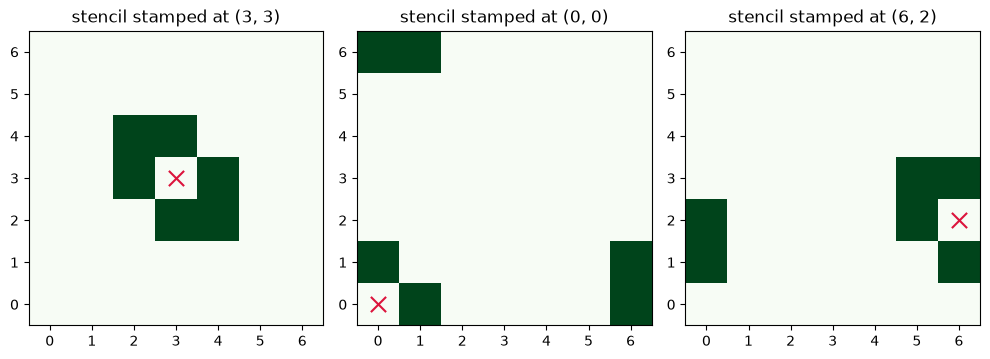

In [3]:
L = 7
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, site in zip(axes, [(3, 3), (0, 0), (6, 2)]):
    delta = np.zeros((L, L), dtype=int)
    delta[site] = 1
    ax.imshow(gsd.ring_mul(f.on((L, L)), delta).T, cmap="Greens", origin="lower", vmin=0, vmax=1)
    ax.scatter(*site, marker="x", s=120, color="crimson")
    ax.set_title(f"stencil stamped at {site}")
    ax.set_xticks(range(L)), ax.set_yticks(range(L))
plt.tight_layout()

Stacking all $L_xL_y$ impulse responses as columns gives $M_f$, the matrix of "multiply by $f$". Because
multiplying by $x$ is a cyclic shift, every column is a shifted copy of the first: $M_f$ is circulant in
1D and block-circulant in 2D.

every column has six ones: {6}   symmetric (f = f-bar): True


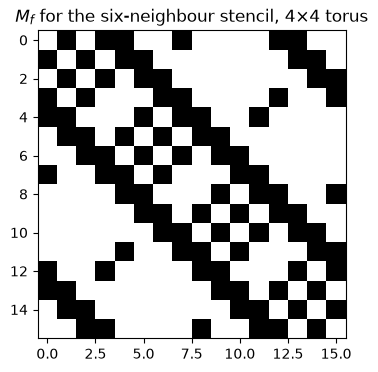

In [4]:
M = gsd.mult_matrix(f, (4, 4))
plt.figure(figsize=(4, 4))
plt.imshow(M, cmap="Greys", interpolation="nearest")
plt.title("$M_f$ for the six-neighbour stencil, 4×4 torus")
print("every column has six ones:", {int(c) for c in M.sum(0)}, "  symmetric (f = f-bar):", (M == M.T).all())

## 3. Terms, relations and symmetries

Read the stencil as a classical Hamiltonian, one multi-spin term per site:

$$H=-\sum_r O_r,\qquad O_r=\prod_{s\in f} Z_{r+s}.$$

The check matrix $F$ has one row per term and one column per spin: $F=M_f^{\mathsf T}$. Two kernels
matter, and they always have the same dimension because $\operatorname{rank}F=\operatorname{rank}F^{\mathsf T}$:

* **symmetries** $\ker F$: flip patterns $u$ that leave every term invariant ($F u = 0$, i.e. $\bar f\cdot u=0$);
* **relations** $\ker F^{\mathsf T}$: exponents $t$ with $\prod_r O_r^{t_r}=\mathbb 1$ ($f\cdot t=0$).

Each relation lowers the rank of $F$ by one, and $\log_2\mathrm{GSD}=n-\operatorname{rank}F$. For a
classical single-stencil model the symmetry group acts simply transitively on the ground states, so
counting either one counts the other.

The validation below checks a kernel four independent ways: against the *rolling* code rather than the
matrix, for independence, for rank–nullity, and for closure under random combinations.

In [5]:
def validate(f, shape, p=2, n_random=8):
    model = gsd.classical("m", f)
    F = model.check_matrix(shape, p)[:, -np.prod(shape):]      # the Z block
    S = model.symmetries(shape, p)
    fbar = f.bar().on(shape, p)
    in_kernel = all(not gsd.ring_mul(fbar, u.reshape(shape), p).any() for u in S)
    independent = gsd.rank(S, p) == len(S)
    rank_nullity = gsd.rank(F, p) + len(S) == np.prod(shape)
    closed = all(not gsd.ring_mul(fbar, ((rng.integers(0, p, len(S)) @ S) % p).reshape(shape), p).any()
                 for _ in range(n_random))
    return len(S), bool(in_kernel), bool(independent), bool(rank_nullity), bool(closed)

for shape, p in [((4, 4), 2), ((6, 5), 2), ((5, 3), 3)]:
    print(shape, f"p={p}", "-> dim, in kernel, independent, rank-nullity, subspace:", validate(f, shape, p))

(4, 4) p=2 -> dim, in kernel, independent, rank-nullity, subspace: (10, True, True, True, True)
(6, 5) p=2 -> dim, in kernel, independent, rank-nullity, subspace: (10, True, True, True, True)
(5, 3) p=3 -> dim, in kernel, independent, rank-nullity, subspace: (2, True, True, True, True)


## 4. Six neighbours over $GF(2)$: smooth and linear

Sweeping the torus size gives a clean pattern,

$$\log_2\mathrm{GSD}=L_x+L_y+\gcd(L_x,L_y)-2 .$$

In [6]:
six = gsd.classical("six", f)
Ls = range(2, 13)
grid = np.array([[six.log_gsd((lx, ly)) for lx in Ls] for ly in Ls])
assert all(grid[b, a] == lx + ly + gcd(lx, ly) - 2 for a, lx in enumerate(Ls) for b, ly in enumerate(Ls))
print("all", grid.size, "tori match  Lx + Ly + gcd(Lx, Ly) - 2")
print(grid)

all 121 tori match  Lx + Ly + gcd(Lx, Ly) - 2
[[ 4  4  6  6  8  8 10 10 12 12 14]
 [ 4  7  6  7 10  9 10 13 12 13 16]
 [ 6  6 10  8 10 10 14 12 14 14 18]
 [ 6  7  8 13 10 11 12 13 18 15 16]
 [ 8 10 10 10 16 12 14 16 16 16 22]
 [ 8  9 10 11 12 19 14 15 16 17 18]
 [10 10 14 12 14 14 22 16 18 18 22]
 [10 13 12 13 16 15 16 25 18 19 22]
 [12 12 14 18 16 16 18 18 28 20 22]
 [12 13 14 15 16 17 18 19 20 31 22]
 [14 16 18 16 22 18 22 22 22 22 34]]


The polynomial explains it. Up to the unit $xy$,

$$xy\,f = x^2+y^2+x+y+x^2y+xy^2 \;=\; (1+x)(1+y)(x+y)\pmod 2 .$$

Each factor is one lattice direction: $1+x$ is killed by patterns constant along $x$, $1+y$ by patterns
constant along $y$, and $x+y$ by patterns constant along the diagonal, which closes into
$\gcd(L_x,L_y)$ classes on the torus. Three families of stripes, $L_x+L_y+\gcd$ of them, minus the
overlaps. The stencil *factors direction by direction*, and that is the signature of ordinary
(non-fractal) subsystem symmetries.

In [7]:
for p, factors in {2: ["1 + x", "1 + y", "x + y"], 3: ["1 + x + y", "xy + x + y"]}.items():
    prod = Poly("1")
    for g in factors:
        prod = prod * Poly(g)
    print(f"p={p}:  {' * '.join('(' + g + ')' for g in factors)} = xy f :",
          prod.mod(p) == (Poly("xy") * f).mod(p))

p=2:  (1 + x) * (1 + y) * (x + y) = xy f : True
p=3:  (1 + x + y) * (xy + x + y) = xy f : True


## 5. The same stencil over $GF(3)$: sparse and number-theoretic

One different prime and the character changes completely. Over $GF(3)$, $xy\,f=(1+x+y)(xy+x+y)$: two
factors, neither a product of one-variable pieces. No stripes to count; instead the degeneracy is
mostly flat with spikes at arithmetically special sizes. The floor of 1 is the uniform configuration:
every site sees six neighbours and $6\equiv0 \pmod 3$ (also mod 2, but not mod 5 or 7).

In [8]:
squares = list(range(2, 28))
for p in (2, 3, 5, 7):
    print(f"p={p}:", [six.log_gsd(L, p) for L in squares[:11]])
nc3 = [six.log_gsd(L, 3) for L in squares]
print("\np = 3, sizes with log_3 GSD > 1:", [(L, n) for L, n in zip(squares, nc3) if n > 1])

p=2: [4, 7, 10, 13, 16, 19, 22, 25, 28, 31, 34]


p=3: [1, 6, 1, 1, 6, 1, 13, 18, 1, 1, 6]
p=5: [0, 6, 0, 0, 6, 0, 12, 6, 0, 0, 6]
p=7: [0, 6, 0, 0, 6, 0, 12, 6, 0, 0, 6]



p = 3, sizes with log_3 GSD > 1: [(3, 6), (6, 6), (8, 13), (9, 18), (12, 6), (13, 13), (15, 6), (16, 13), (18, 18), (21, 6), (24, 42), (26, 49), (27, 54)]


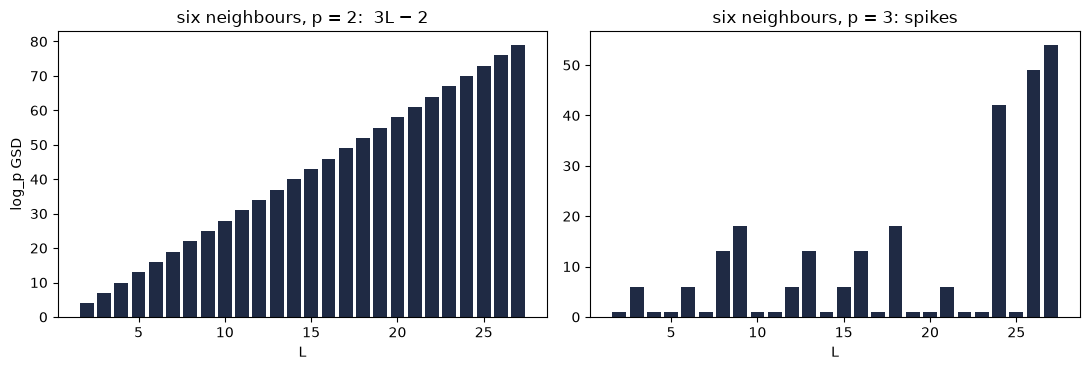

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(squares, [3 * L - 2 for L in squares], color="#1f2a44")
ax[0].set_title("six neighbours, p = 2:  3L − 2")
ax[1].bar(squares, nc3, color="#1f2a44")
ax[1].set_title("six neighbours, p = 3: spikes")
for a in ax:
    a.set_xlabel("L")
ax[0].set_ylabel("log_p GSD")
plt.tight_layout()

Over $\mathbb Z_3$ a relation can use a term *twice* (entries equal to 2), which has no qubit analogue:

In [10]:
S = six.symmetries((3, 3), 3)
print(f"3x3, p=3: {len(S)} independent symmetries; the first two:\n", S[0].reshape(3, 3), "\n", S[1].reshape(3, 3))

3x3, p=3: 6 independent symmetries; the first two:
 [[0 0 2]
 [1 0 0]
 [0 0 0]] 
 [[2 0 0]
 [0 1 0]
 [0 0 0]]


## 6. Letting the algebra do the work

Brute force builds an $N\times N$ matrix ($N=L_xL_y$) and eliminates it in $O(N^3)$. The ring knows more.

**Kernel = quotient.** A group ring is a *Frobenius algebra*: for any ideal $I$, $\dim\operatorname{Ann}(I)=\dim R/I$.
The relations are $\operatorname{Ann}(f)$, so

$$\log_p\mathrm{GSD} \;=\; \dim_{\mathbb F_p} R/(f).$$

**Eliminate a variable.** If $f$ is linear in one variable, $f=y+g(x)$, then modulo $f$ we may replace
$y$ by $g(x)$ everywhere. The relation $y^{L_y}=1$ becomes $g(x)^{L_y}=1$, and

$$R/(f)\;\cong\;\mathbb F_p[x]/\big(x^{L_x}-1,\ g(x)^{L_y}-1\big),$$

a ring in **one** variable. $\mathbb F_p[x]$ is a principal ideal domain, so its dimension is a single
gcd degree: $\log_2\mathrm{GSD}=\deg\gcd(x^{L_x}+1,\ g(x)^{L_y}+1)$. For Newman–Moore, $g=1+x$.

`gsd.quotient_dim` performs that elimination automatically whenever a generator is linear in some
variable, and falls back to brute force otherwise. All three routes agree:

In [11]:
nm = gsd.NEWMAN_MOORE
for L in (15, 31, 63, 64):
    t0 = time.perf_counter(); brute = nm.log_gsd(L, method="brute"); t1 = time.perf_counter()
    alg = nm.log_gsd(L); t2 = time.perf_counter()
    gcd_form = gsd.closed_form.newman_moore_family(L, L)
    print(f"L={L:3d}  brute {brute:3d} ({t1 - t0:5.2f}s)   algebra {alg:3d} ({t2 - t1:5.3f}s)   gcd {gcd_form:3d}")

L= 15  brute  14 ( 0.00s)   algebra  14 (0.000s)   gcd  14
L= 31  brute  30 ( 0.02s)   algebra  30 (0.001s)   gcd  30


L= 63  brute  62 ( 0.31s)   algebra  62 (0.002s)   gcd  62


L= 64  brute   0 ( 0.44s)   algebra   0 (0.001s)   gcd   0


The six-neighbour stencil is not linear in any variable, so it gets no shortcut, but the identity
$\log\mathrm{GSD}=\dim R/(f)$ still holds; the elimination step is what fails, not the identity.

## 7. Your turn

Any polynomial is a model. A few to try: `"1 + x + y + xy"` (does it factor?), `"1 + x + x^2 + y"`
(the trinomial of notebook 04), `"1 + x + y"` over `p=3`, or `"1 + xy + x^2"`.

In [12]:
mine = gsd.classical("mine", "1 + x + y + xy")
print("f =", mine.generators[0].z[0])
print("log2 GSD for L = 2..16:", [mine.log_gsd(L) for L in range(2, 17)])

f = 1 + x + y + xy
log2 GSD for L = 2..16: [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31]
